In [1]:
import os

# 1) Find every folder that contains DR / No_DR class folders
found = []
for root, dirs, files in os.walk("/kaggle/input"):
    if "DR" in dirs and "No_DR" in dirs:
        found.append(root)
        n_dr = len(os.listdir(os.path.join(root, "DR")))
        n_nodr = len(os.listdir(os.path.join(root, "No_DR")))
        print(f"{root}  ->  DR: {n_dr}, No_DR: {n_nodr}")

# 2) Show the top-level structure of whatever is attached
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.replace("/kaggle/input", "").count(os.sep)
    if depth <= 3:
        print(root, "| folders:", dirs[:6], "| files:", len(files))

print("\nFound:", found)

/kaggle/input/datasets/mairazainab/gndataset/Diagnosis of Diabetic Retinopathy/valid  ->  DR: 245, No_DR: 286
/kaggle/input/datasets/mairazainab/gndataset/Diagnosis of Diabetic Retinopathy/test  ->  DR: 113, No_DR: 118
/kaggle/input/datasets/mairazainab/gndataset/Diagnosis of Diabetic Retinopathy/train  ->  DR: 1050, No_DR: 1026
/kaggle/input/datasets/mairazainab/gndataset/retino/valid  ->  DR: 245, No_DR: 286
/kaggle/input/datasets/mairazainab/gndataset/retino/test  ->  DR: 113, No_DR: 118
/kaggle/input/datasets/mairazainab/gndataset/retino/train  ->  DR: 1050, No_DR: 1026
/kaggle/input | folders: ['datasets'] | files: 0
/kaggle/input/datasets | folders: ['mairazainab'] | files: 0
/kaggle/input/datasets/mairazainab | folders: ['gndataset'] | files: 0
/kaggle/input/datasets/mairazainab/gndataset | folders: ['Diagnosis of Diabetic Retinopathy', 'retino'] | files: 0

Found: ['/kaggle/input/datasets/mairazainab/gndataset/Diagnosis of Diabetic Retinopathy/valid', '/kaggle/input/datasets/ma

In [2]:
import numpy as np, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc

BASE = "/kaggle/input/datasets/mairazainab/gndataset/retino"
TRAIN_DIR = f"{BASE}/train"
VALID_DIR = f"{BASE}/valid"
TEST_DIR  = f"{BASE}/test"

IMG_SIZE, BATCH, EPOCHS = (224, 224), 32, 40

def load(path, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        path, labels="inferred", label_mode="binary",
        image_size=IMG_SIZE, batch_size=BATCH, shuffle=shuffle)

train_ds      = load(TRAIN_DIR, True)     # for training
train_eval_ds = load(TRAIN_DIR, False)    # fixed order, for train confusion matrix/ROC
valid_ds      = load(VALID_DIR, False)
test_ds       = load(TEST_DIR, False)

class_names = test_ds.class_names         # ['DR', 'No_DR'] -> DR=0, No_DR=1
print(class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds, train_eval_ds, valid_ds, test_ds = [
    d.cache().prefetch(AUTOTUNE) for d in (train_ds, train_eval_ds, valid_ds, test_ds)]

Found 2076 files belonging to 2 classes.


I0000 00:00:1792403480.561245      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792403480.564727      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 2076 files belonging to 2 classes.
Found 531 files belonging to 2 classes.
Found 231 files belonging to 2 classes.
['DR', 'No_DR']


In [3]:
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

def inception_module(x, f1, f3_red, f3, f5_red, f5, pool_proj, name):
    b1 = layers.Conv2D(f1, 1, padding="same", activation="relu", name=f"{name}_1x1")(x)

    b2 = layers.Conv2D(f3_red, 1, padding="same", activation="relu", name=f"{name}_3x3_reduce")(x)
    b2 = layers.Conv2D(f3, 3, padding="same", activation="relu", name=f"{name}_3x3")(b2)

    b3 = layers.Conv2D(f5_red, 1, padding="same", activation="relu", name=f"{name}_5x5_reduce")(x)
    b3 = layers.Conv2D(f5, 5, padding="same", activation="relu", name=f"{name}_5x5")(b3)

    b4 = layers.MaxPooling2D(3, strides=1, padding="same", name=f"{name}_pool")(x)
    b4 = layers.Conv2D(pool_proj, 1, padding="same", activation="relu", name=f"{name}_pool_proj")(b4)

    return layers.Concatenate(name=f"{name}_concat")([b1, b2, b3, b4])

def build_googlenet(input_shape=IMG_SIZE + (3,)):
    inp = layers.Input(shape=input_shape)
    x = augment(inp)                          # active only during training
    x = layers.Rescaling(1./255)(x)

    x = layers.Conv2D(64, 7, strides=2, padding="same", activation="relu", name="conv1")(x)
    x = layers.MaxPooling2D(3, strides=2, padding="same", name="pool1")(x)
    x = layers.BatchNormalization(name="bn1")(x)
    x = layers.Conv2D(64, 1, padding="same", activation="relu", name="conv2_reduce")(x)
    x = layers.Conv2D(192, 3, padding="same", activation="relu", name="conv2")(x)
    x = layers.BatchNormalization(name="bn2")(x)
    x = layers.MaxPooling2D(3, strides=2, padding="same", name="pool2")(x)

    x = inception_module(x, 64, 96, 128, 16, 32, 32, "inception_3a")
    x = inception_module(x, 128, 128, 192, 32, 96, 64, "inception_3b")
    x = layers.MaxPooling2D(3, strides=2, padding="same", name="pool3")(x)

    x = inception_module(x, 192, 96, 208, 16, 48, 64, "inception_4a")
    x = inception_module(x, 160, 112, 224, 24, 64, 64, "inception_4b")
    x = inception_module(x, 128, 128, 256, 24, 64, 64, "inception_4c")
    x = inception_module(x, 112, 144, 288, 32, 64, 64, "inception_4d")
    x = inception_module(x, 256, 160, 320, 32, 128, 128, "inception_4e")
    x = layers.MaxPooling2D(3, strides=2, padding="same", name="pool4")(x)

    x = inception_module(x, 256, 160, 320, 32, 128, 128, "inception_5a")
    x = inception_module(x, 384, 192, 384, 48, 128, 128, "inception_5b")

    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.4, name="dropout")(x)
    out = layers.Dense(1, activation="sigmoid", name="output")(x)
    return models.Model(inp, out, name="GoogLeNet")

model = build_googlenet()
model.summary()

model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss="binary_crossentropy", metrics=["accuracy"])

Model: "GoogLeNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ sequential[0][0]  │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1 (Conv2D)      │ (None, 112, 112,  │      9,472 │ rescaling[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ conv1[0][0]       │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn1                 │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_reduce        │ (None, 56, 56,    │      4,160 │ bn1[0][0]         │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2 (Conv2D)      │ (None, 56, 56,    │    110,784 │ conv2_reduce[0][… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn2                 │ (None, 56, 56,    │        768 │ conv2[0][0]       │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool2               │ (None, 28, 28,    │          0 │ bn2[0][0]         │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_3x3_r… │ (None, 28, 28,    │     18,528 │ pool2[0][0]       │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_5x5_r… │ (None, 28, 28,    │      3,088 │ pool2[0][0]       │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_pool   │ (None, 28, 28,    │          0 │ pool2[0][0]       │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_1x1    │ (None, 28, 28,    │     12,352 │ pool2[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_3x3    │ (None, 28, 28,    │    110,720 │ inception_3a_3x3… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_5x5    │ (None, 28, 28,    │     12,832 │ inception_3a_5x5… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_pool_… │ (None, 28, 28,    │      6,176 │ inception_3a_poo

 Total params: 5,975,601 (22.80 MB)

 Trainable params: 5,975,089 (22.79 MB)

 Non-trainable params: 512 (2.00 KB)

In [4]:
cbs = [
    callbacks.ModelCheckpoint("googlenet_best.keras", monitor="val_accuracy",
                              save_best_only=True, mode="max"),
    callbacks.EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
]

hist = model.fit(train_ds, validation_data=valid_ds, epochs=EPOCHS, callbacks=cbs)

Epoch 1/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 36s 236ms/step - accuracy: 0.7346 - loss: 0.4929 - val_accuracy: 0.4614 - val_loss: 0.7000 - learning_rate: 1.0000e-04
Epoch 2/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 9s 138ms/step - accuracy: 0.9037 - loss: 0.2670 - val_accuracy: 0.4614 - val_loss: 0.7145 - learning_rate: 1.0000e-04
Epoch 3/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 9s 139ms/step - accuracy: 0.9152 - loss: 0.2306 - val_accuracy: 0.4614 - val_loss: 0.7404 - learning_rate: 1.0000e-04
Epoch 4/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 9s 141ms/step - accuracy: 0.9277 - loss: 0.2015 - val_accuracy: 0.4614 - val_loss: 0.7769 - learning_rate: 1.0000e-04
Epoch 5/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 10s 152ms/step - accuracy: 0.9379 - loss: 0.1799 - val_accuracy: 0.5217 - val_loss: 0.6464 - learning_rate: 5.0000e-05
Epoch 6/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 10s 152ms/step - accuracy: 0.9432 - loss: 0.1621 - val_accuracy: 0.8098 - val_loss: 0.4737 - learning_rate: 5.0000e-05
Epoch 7/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 10s 154ms/step - accura

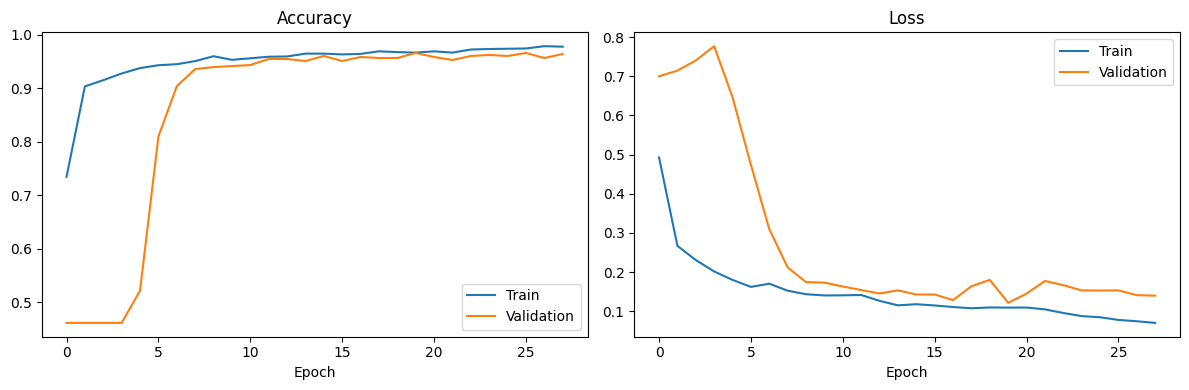

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist.history["accuracy"], label="Train")
ax[0].plot(hist.history["val_accuracy"], label="Validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(hist.history["loss"], label="Train")
ax[1].plot(hist.history["val_loss"], label="Validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

Epoch 1/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 25s 186ms/step - accuracy: 0.7847 - loss: 0.4473 - val_accuracy: 0.4614 - val_loss: 0.7052 - learning_rate: 1.0000e-04
Epoch 2/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 11s 173ms/step - accuracy: 0.9017 - loss: 0.2526 - val_accuracy: 0.4614 - val_loss: 0.7275 - learning_rate: 1.0000e-04
Epoch 3/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 12s 181ms/step - accuracy: 0.9138 - loss: 0.2293 - val_accuracy: 0.4614 - val_loss: 0.7652 - learning_rate: 1.0000e-04
Epoch 4/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 11s 172ms/step - accuracy: 0.9345 - loss: 0.1921 - val_accuracy: 0.4614 - val_loss: 0.8420 - learning_rate: 5.0000e-05
Epoch 5/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 11s 165ms/step - accuracy: 0.9369 - loss: 0.1876 - val_accuracy: 0.4614 - val_loss: 0.8916 - learning_rate: 5.0000e-05
Epoch 6/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 10s 162ms/step - accuracy: 0.9441 - loss: 0.1741 - val_accuracy: 0.4614 - val_loss: 0.9218 - learning_rate: 5.0000e-05
Epoch 7/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 10s 161ms/step - acc

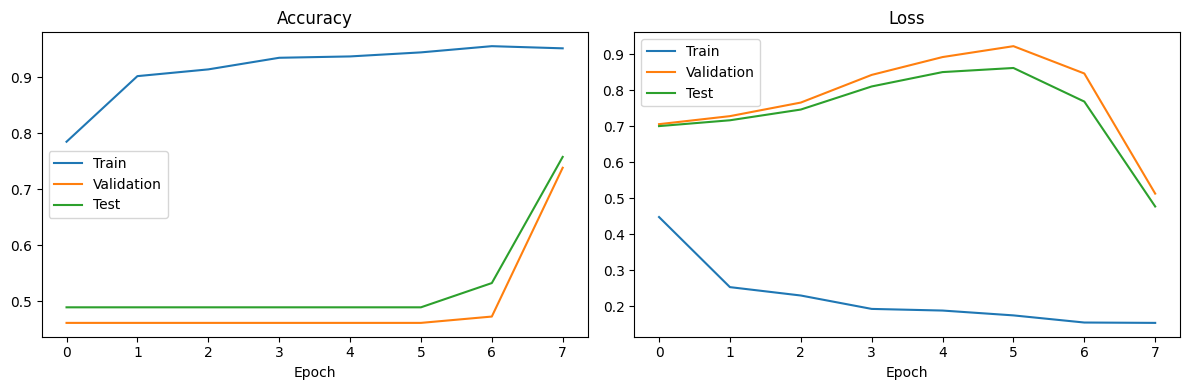

In [6]:
class TestHistory(callbacks.Callback):
    def __init__(self, data):
        super().__init__()
        self.data = data
        self.test_loss, self.test_acc = [], []
    def on_epoch_end(self, epoch, logs=None):
        loss, acc = self.model.evaluate(self.data, verbose=0)
        self.test_loss.append(loss); self.test_acc.append(acc)

test_cb = TestHistory(test_ds)

model = build_googlenet()
model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss="binary_crossentropy", metrics=["accuracy"])

hist = model.fit(train_ds, validation_data=valid_ds, epochs=EPOCHS,
                 callbacks=cbs + [test_cb])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist.history["accuracy"], label="Train")
ax[0].plot(hist.history["val_accuracy"], label="Validation")
ax[0].plot(test_cb.test_acc, label="Test")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()

ax[1].plot(hist.history["loss"], label="Train")
ax[1].plot(hist.history["val_loss"], label="Validation")
ax[1].plot(test_cb.test_loss, label="Test")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

Train: acc=0.5058, loss=0.6963
Valid: acc=0.4614, loss=0.7052
Test : acc=0.4892, loss=0.6998


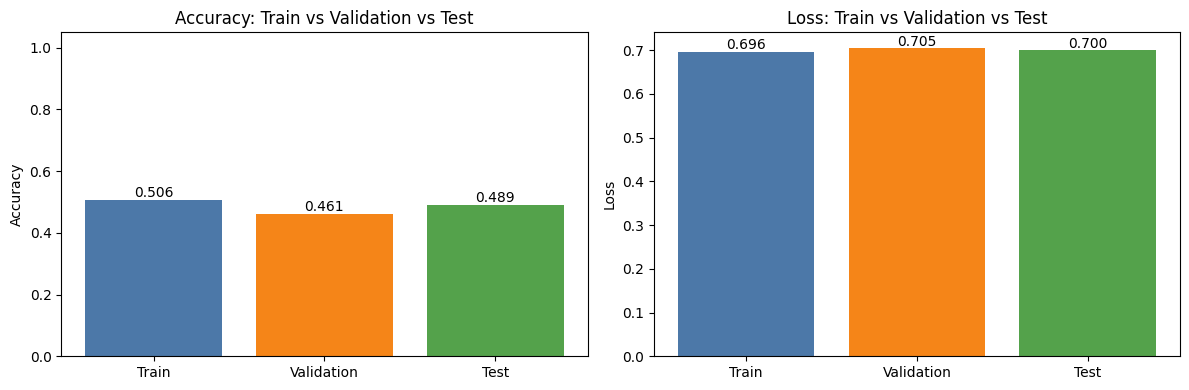

In [7]:
# Evaluate on all three sets
tr_loss, tr_acc = model.evaluate(train_eval_ds, verbose=0)
va_loss, va_acc = model.evaluate(valid_ds, verbose=0)
te_loss, te_acc = model.evaluate(test_ds, verbose=0)

print(f"Train: acc={tr_acc:.4f}, loss={tr_loss:.4f}")
print(f"Valid: acc={va_acc:.4f}, loss={va_loss:.4f}")
print(f"Test : acc={te_acc:.4f}, loss={te_loss:.4f}")

# Bar graphs
sets = ["Train", "Validation", "Test"]
accs = [tr_acc, va_acc, te_acc]
losses = [tr_loss, va_loss, te_loss]
colors = ["#4C78A8", "#F58518", "#54A24B"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].bar(sets, accs, color=colors)
ax[0].set_title("Accuracy: Train vs Validation vs Test")
ax[0].set_ylim(0, 1.05); ax[0].set_ylabel("Accuracy")
for i, v in enumerate(accs):
    ax[0].text(i, v + 0.01, f"{v:.3f}", ha="center")

ax[1].bar(sets, losses, color=colors)
ax[1].set_title("Loss: Train vs Validation vs Test")
ax[1].set_ylabel("Loss")
for i, v in enumerate(losses):
    ax[1].text(i, v + 0.005, f"{v:.3f}", ha="center")

plt.tight_layout(); plt.show()

65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step


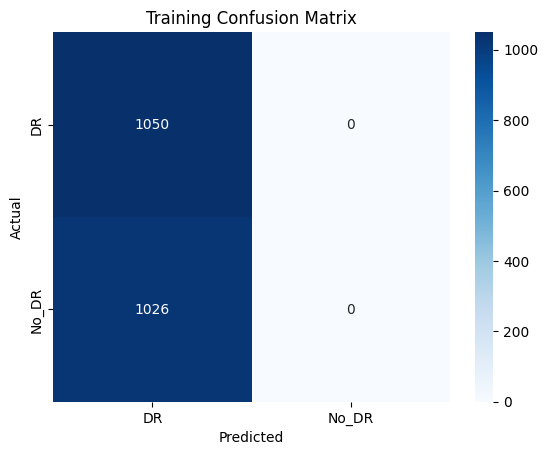

Train accuracy: 0.5057803468208093
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


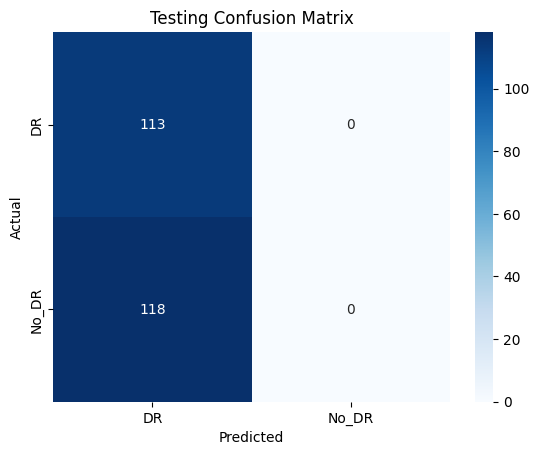

Test accuracy: 0.48917748917748916
              precision    recall  f1-score   support

          DR       0.49      1.00      0.66       113
       No_DR       0.00      0.00      0.00       118

    accuracy                           0.49       231
   macro avg       0.24      0.50      0.33       231
weighted avg       0.24      0.49      0.32       231



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


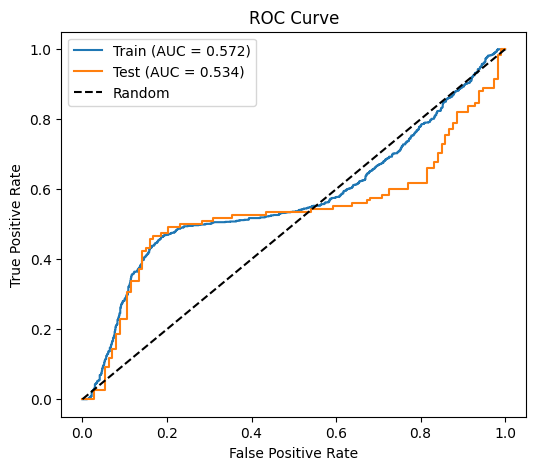

In [8]:
def get_preds(ds):
    y_true = np.concatenate([y.numpy().ravel() for _, y in ds]).astype(int)
    y_prob = model.predict(ds).ravel()
    return y_true, y_prob, (y_prob > 0.5).astype(int)

def show_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(title); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

# Training set
ytr, ptr, prtr = get_preds(train_eval_ds)
show_cm(ytr, prtr, "Training Confusion Matrix")
print("Train accuracy:", (ytr == prtr).mean())

# Test set
yte, pte, prte = get_preds(test_ds)
show_cm(yte, prte, "Testing Confusion Matrix")
print("Test accuracy:", (yte == prte).mean())
print(classification_report(yte, prte, target_names=class_names))

# ROC curves
plt.figure(figsize=(6, 5))
for y, p, label in [(ytr, ptr, "Train"), (yte, pte, "Test")]:
    fpr, tpr, _ = roc_curve(y, p)
    plt.plot(fpr, tpr, label=f"{label} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend(); plt.show()

In [9]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf

# 1) Standard summary
model.summary()

Model: "GoogLeNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ sequential[1][0]  │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1 (Conv2D)      │ (None, 112, 112,  │      9,472 │ rescaling_1[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ conv1[0][0]       │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn1                 │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_reduce        │ (None, 56, 56,    │      4,160 │ bn1[0][0]         │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2 (Conv2D)      │ (None, 56, 56,    │    110,784 │ conv2_reduce[0][… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn2                 │ (None, 56, 56,    │        768 │ conv2[0][0]       │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool2               │ (None, 28, 28,    │          0 │ bn2[0][0]         │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_3x3_r… │ (None, 28, 28,    │     18,528 │ pool2[0][0]       │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_5x5_r… │ (None, 28, 28,    │      3,088 │ pool2[0][0]       │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_pool   │ (None, 28, 28,    │          0 │ pool2[0][0]       │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_1x1    │ (None, 28, 28,    │     12,352 │ pool2[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_3x3    │ (None, 28, 28,    │    110,720 │ inception_3a_3x3… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_5x5    │ (None, 28, 28,    │     12,832 │ inception_3a_5x5… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_3a_pool_… │ (None, 28, 28,    │      6,176 │ inception_3a_poo

 Total params: 17,925,781 (68.38 MB)

 Trainable params: 5,975,089 (22.79 MB)

 Non-trainable params: 512 (2.00 KB)

 Optimizer params: 11,950,180 (45.59 MB)


Total params         : 5,975,601
Trainable params     : 5,975,089
Non-trainable params : 512
                  Layer                   Type         Output Shape  Params                                          What it does
          input_layer_2             InputLayer  (None, 224, 224, 3)       0                   Receives the 224x224x3 fundus image
             sequential             Sequential  (None, 224, 224, 3)       0 Data augmentation (flip, rotate, zoom), training only
            rescaling_1              Rescaling  (None, 224, 224, 3)       0                 Scales pixel values from 0-255 to 0-1
                  conv1                 Conv2D (None, 112, 112, 64)    9472               7x7 stem conv: basic edges and textures
                  pool1           MaxPooling2D   (None, 56, 56, 64)       0                              Downsamples feature maps
                    bn1     BatchNormalization   (None, 56, 56, 64)     256           Normalizes activations; stabilizes train

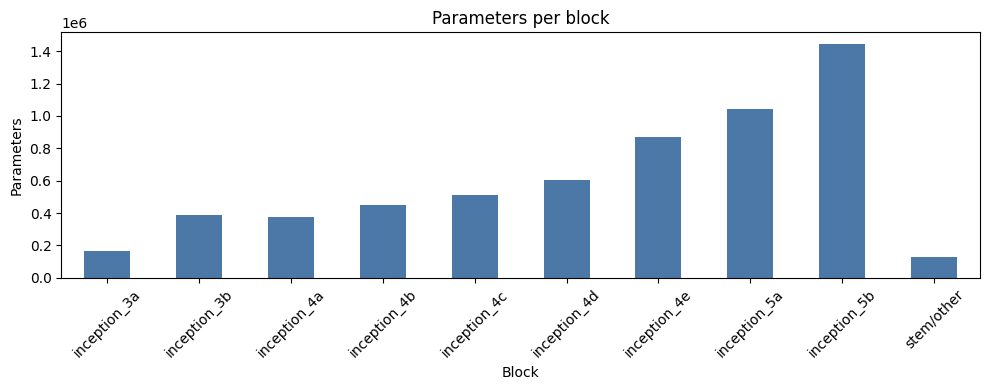

In [10]:
total = int(model.count_params())
trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
non_trainable = total - trainable
print(f"\nTotal params         : {total:,}")
print(f"Trainable params     : {trainable:,}")
print(f"Non-trainable params : {non_trainable:,}")

# 3) What each layer does
def purpose(layer):
    n, t = layer.name, layer.__class__.__name__
    if t == "InputLayer":             return "Receives the 224x224x3 fundus image"
    if t == "Sequential":             return "Data augmentation (flip, rotate, zoom), training only"
    if t == "Rescaling":              return "Scales pixel values from 0-255 to 0-1"
    if t == "BatchNormalization":     return "Normalizes activations; stabilizes training"
    if t == "Concatenate":            return "Joins the 4 inception branches"
    if t == "GlobalAveragePooling2D": return "Averages each feature map to one value"
    if t == "Dropout":                return "Randomly drops 40% of units to reduce overfitting"
    if t == "Dense":                  return "Sigmoid output: probability of No_DR"
    if t == "MaxPooling2D":
        return "Pooling in inception branch 4" if "inception" in n else "Downsamples feature maps"
    if t == "Conv2D":
        if n == "conv1":              return "7x7 stem conv: basic edges and textures"
        if "reduce" in n:             return "1x1 conv: reduces channels before 3x3/5x5"
        if n.endswith("_1x1"):        return "Inception branch 1: 1x1 conv"
        if n.endswith("_3x3"):        return "Inception branch 2: 3x3 conv"
        if n.endswith("_5x5"):        return "Inception branch 3: 5x5 conv"
        if "pool_proj" in n:          return "Inception branch 4: 1x1 conv after pooling"
        return "Conv layer: extracts features"
    return ""

rows = []
for l in model.layers:
    try:
        shape = str(tuple(l.output.shape))
    except Exception:
        shape = "-"
    rows.append([l.name, l.__class__.__name__, shape, int(l.count_params()), purpose(l)])

df = pd.DataFrame(rows, columns=["Layer", "Type", "Output Shape", "Params", "What it does"])
print(df.to_string(index=False))

# 4) Parameters per block
df["Block"] = df["Layer"].apply(lambda n: n[:12] if n.startswith("inception_") else "stem/other")
bp = df.groupby("Block")["Params"].sum()
bp = bp[bp > 0]
plt.figure(figsize=(10, 4))
bp.plot(kind="bar", color="#4C78A8")
plt.title("Parameters per block"); plt.ylabel("Parameters"); plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

              DR  No_DR  Total
Train       1050   1026   2076
Validation   245    286    531
Test         113    118    231

Grand total: 2838


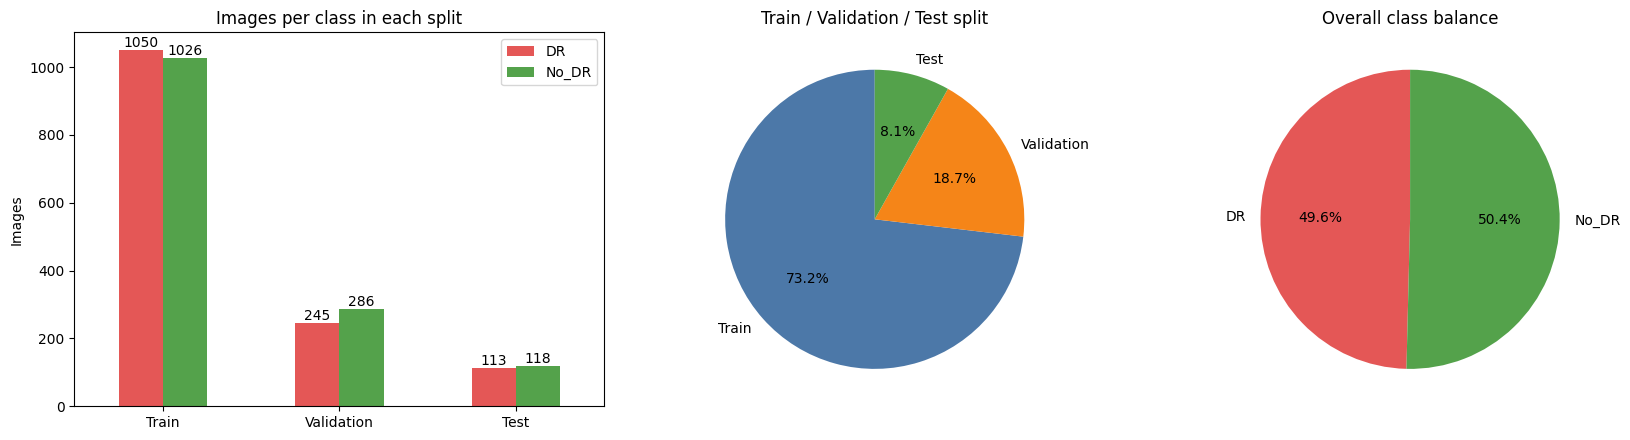

In [11]:
import os, pandas as pd, matplotlib.pyplot as plt

BASE = "/kaggle/input/datasets/mairazainab/gndataset/retino"
TRAIN_DIR, VALID_DIR, TEST_DIR = f"{BASE}/train", f"{BASE}/valid", f"{BASE}/test"

splits = {"Train": TRAIN_DIR, "Validation": VALID_DIR, "Test": TEST_DIR}
counts = {s: {c: len(os.listdir(os.path.join(p, c))) for c in ["DR", "No_DR"]}
          for s, p in splits.items()}
cdf = pd.DataFrame(counts).T
cdf["Total"] = cdf["DR"] + cdf["No_DR"]
print(cdf)
print("\nGrand total:", cdf["Total"].sum())

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

cdf[["DR", "No_DR"]].plot(kind="bar", ax=ax[0], color=["#E45756", "#54A24B"])
ax[0].set_title("Images per class in each split"); ax[0].set_ylabel("Images")
ax[0].tick_params(axis="x", rotation=0)
for c in ax[0].containers:
    ax[0].bar_label(c)

ax[1].pie(cdf["Total"], labels=cdf.index, autopct="%1.1f%%",
          colors=["#4C78A8", "#F58518", "#54A24B"], startangle=90)
ax[1].set_title("Train / Validation / Test split")

tot = cdf[["DR", "No_DR"]].sum()
ax[2].pie(tot, labels=tot.index, autopct="%1.1f%%",
          colors=["#E45756", "#54A24B"], startangle=90)
ax[2].set_title("Overall class balance")

plt.tight_layout(); plt.show()

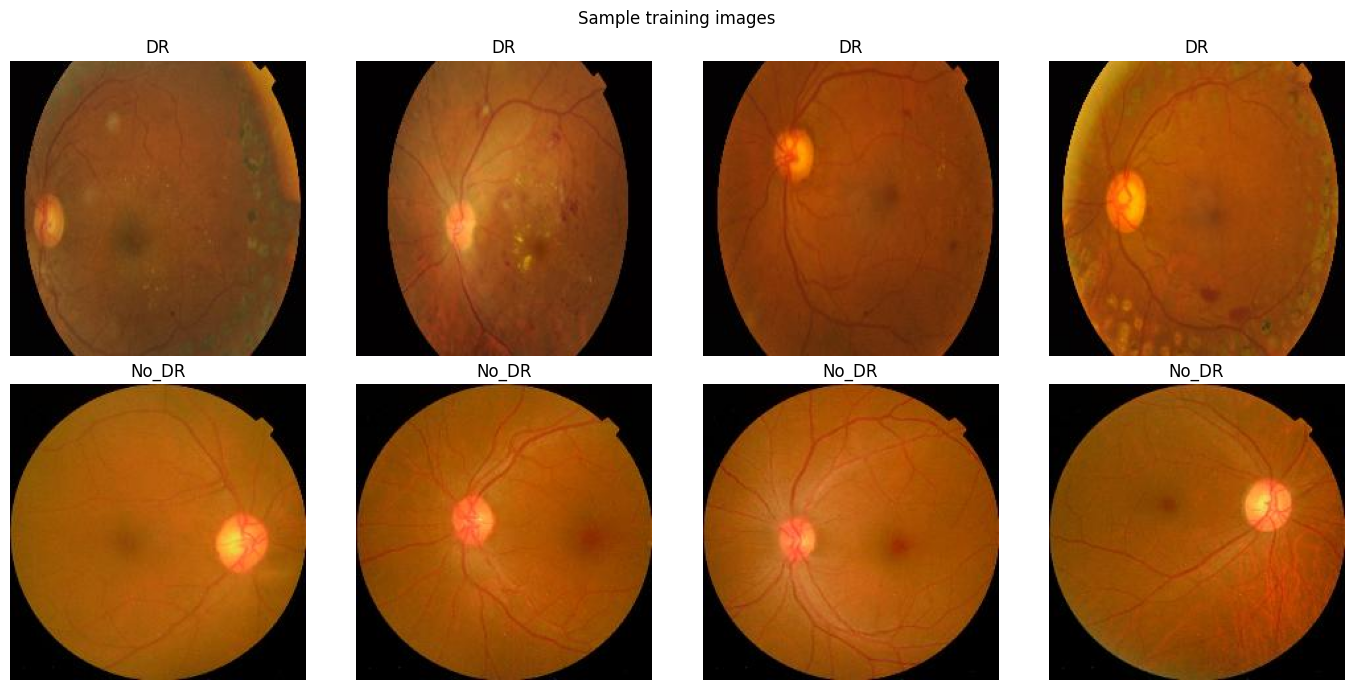

In [12]:
import os, random
import matplotlib.pyplot as plt
from PIL import Image

BASE = "/kaggle/input/datasets/mairazainab/gndataset/retino"
TRAIN_DIR = f"{BASE}/train"

fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for r, cls in enumerate(["DR", "No_DR"]):
    folder = os.path.join(TRAIN_DIR, cls)
    for i, f in enumerate(random.sample(os.listdir(folder), 4)):
        img = Image.open(os.path.join(folder, f)).convert("RGB").resize((224, 224))
        ax[r, i].imshow(img)
        ax[r, i].set_title(cls); ax[r, i].axis("off")
plt.suptitle("Sample training images"); plt.tight_layout(); plt.show()

In [13]:
import numpy as np, pandas as pd
from sklearn.metrics import confusion_matrix

# Reuses yte, prte, pte from the confusion matrix cell. DR is treated as the positive class.
cm = confusion_matrix(yte, prte)            # rows = actual [DR, No_DR]
TP, FN = cm[0, 0], cm[0, 1]
FP, TN = cm[1, 0], cm[1, 1]

sensitivity = TP / (TP + FN)                # recall for DR
specificity = TN / (TN + FP)
precision   = TP / (TP + FP)
accuracy    = (TP + TN) / cm.sum()
f1          = 2 * precision * sensitivity / (precision + sensitivity)

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Sensitivity (Recall)", "Specificity", "Precision", "F1-score"],
    "Value":  [accuracy, sensitivity, specificity, precision, f1]
}).round(4)
print(metrics.to_string(index=False))

              Metric  Value
            Accuracy 0.4892
Sensitivity (Recall) 1.0000
         Specificity 0.0000
           Precision 0.4892
            F1-score 0.6570


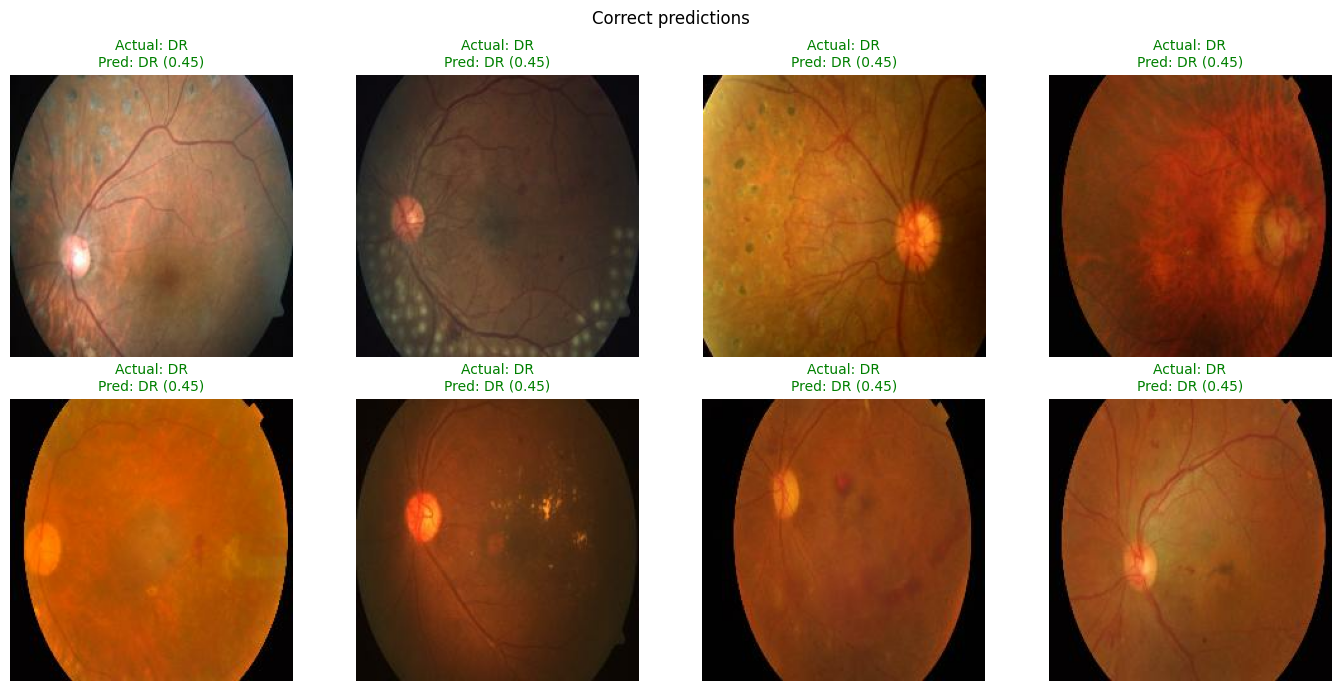

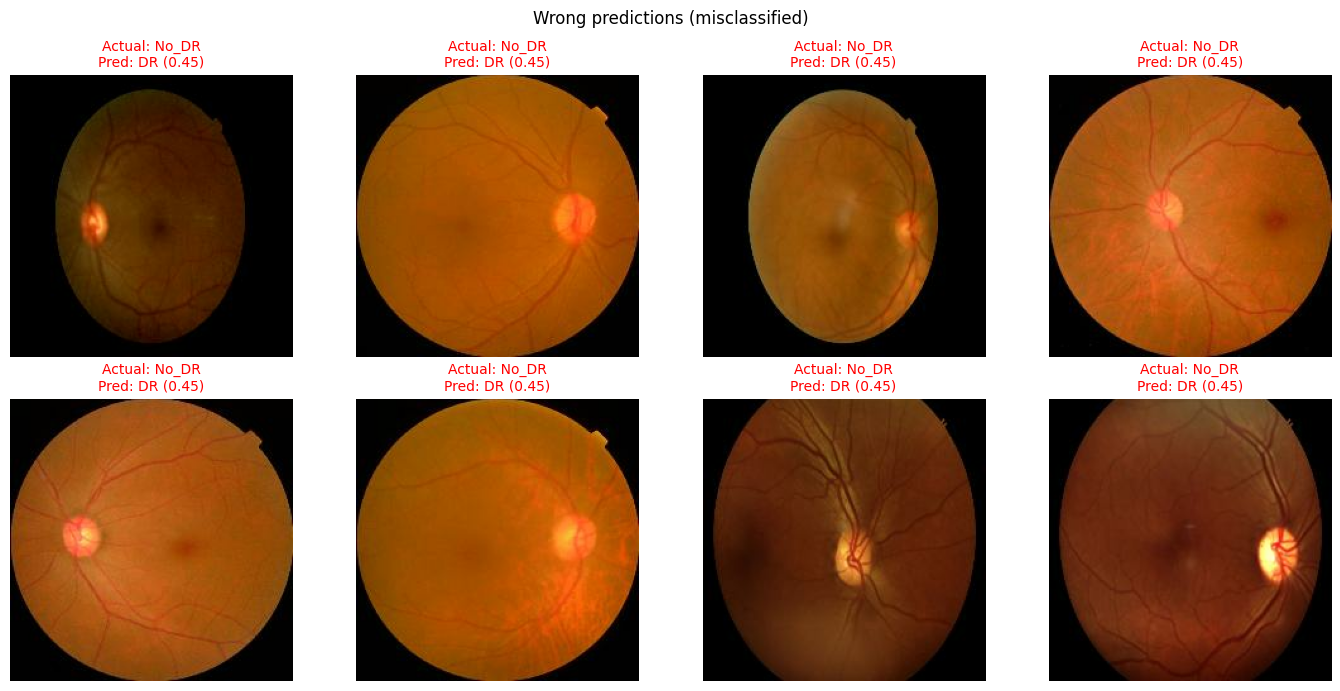

Misclassified: 118 of 231


In [14]:
import matplotlib.pyplot as plt

imgs, labels = [], []
for x, y in test_ds:
    imgs.append(x.numpy()); labels.append(y.numpy().ravel())
imgs = np.concatenate(imgs); labels = np.concatenate(labels).astype(int)
probs = model.predict(imgs, verbose=0).ravel()
preds = (probs > 0.5).astype(int)

def show(idx, title):
    idx = idx[:8]
    if len(idx) == 0:
        print("None to show"); return
    fig, ax = plt.subplots(2, 4, figsize=(14, 7))
    for a in ax.ravel(): a.axis("off")
    for a, i in zip(ax.ravel(), idx):
        a.imshow(imgs[i].astype("uint8"))
        ok = preds[i] == labels[i]
        a.set_title(f"Actual: {class_names[labels[i]]}\nPred: {class_names[preds[i]]} ({probs[i]:.2f})",
                    color="green" if ok else "red", fontsize=10)
    plt.suptitle(title); plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
show(rng.permutation(np.where(preds == labels)[0]), "Correct predictions")
show(np.where(preds != labels)[0], "Wrong predictions (misclassified)")
print("Misclassified:", (preds != labels).sum(), "of", len(labels))

In [15]:
summary = pd.DataFrame({
    "Item": ["Model", "Input size", "Batch size", "Optimizer", "Learning rate (start)",
             "Loss", "Max epochs", "Early stopping", "Augmentation",
             "Train images", "Validation images", "Test images",
             "Total parameters", "Test accuracy"],
    "Value": ["GoogLeNet (Inception v1), from scratch", "224x224x3", BATCH, "Adam", "1e-4",
              "Binary cross-entropy", EPOCHS, "patience 8, val_accuracy",
              "Flip, rotation 0.1, zoom 0.1",
              len(ytr), len(imgs) and sum(len(os.listdir(f"{VALID_DIR}/{c}")) for c in ["DR", "No_DR"]),
              len(yte), f"{model.count_params():,}", f"{accuracy:.4f}"]
})
print(summary.to_string(index=False))

                 Item                                  Value
                Model GoogLeNet (Inception v1), from scratch
           Input size                              224x224x3
           Batch size                                     32
            Optimizer                                   Adam
Learning rate (start)                                   1e-4
                 Loss                   Binary cross-entropy
           Max epochs                                     40
       Early stopping               patience 8, val_accuracy
         Augmentation           Flip, rotation 0.1, zoom 0.1
         Train images                                   2076
    Validation images                                    531
          Test images                                    231
     Total parameters                              5,975,601
        Test accuracy                                 0.4892


In [16]:
from tensorflow.keras.models import load_model

model = load_model("/kaggle/working/googlenet_best.keras")

print("Train [loss, acc]:", model.evaluate(train_eval_ds, verbose=0))
print("Valid [loss, acc]:", model.evaluate(valid_ds, verbose=0))
print("Test  [loss, acc]:", model.evaluate(test_ds, verbose=0))

Train [loss, acc]: [0.09737136960029602, 0.9691714644432068]
Valid [loss, acc]: [0.12130823731422424, 0.9661017060279846]
Test  [loss, acc]: [0.18209189176559448, 0.9610389471054077]
